# Concentration paper


In [10]:
import math
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import functools

def set_seed(s):
    import random
    random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    np.random.seed(s)
    # torch.backends.cudnn.deterministic = True
    # torch.backends.cudnn.benchmark = False

set_seed(0)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class ScaledSigmoid(nn.Module):
    def __init__(self, min_val, max_val):
        super(ScaledSigmoid, self).__init__()
        self.min_val = min_val
        self.max_val = max_val

    def forward(self, x):
        # Apply sigmoid to squish the output to (0, 1)
        x = torch.sigmoid(x)
        # Scale and shift to the desired range [min_val, max_val]
        return self.min_val + x * (self.max_val - self.min_val)

class EquationValue(nn.Module):
    def __init__(self, input_dims, min_val, max_val):
        super().__init__()
        assert min_val < max_val, "min_val must be less than max_val"
        self.min_val = min_val
        self.max_val = max_val
        self.scaled_sigmoid = ScaledSigmoid(min_val, max_val)
        self.input_dims = input_dims
        self.linear = nn.Linear(input_dims, 1)     

        # # Target a pre-activation range of approximately [-4, 4].
        # # If we assume inputs are roughly unit variance, then scale the weights:
        # weight_range = self.max_val / math.sqrt(input_dims)  # This is a heuristic value.
        # nn.init.uniform_(self.linear.weight, -weight_range, weight_range)
        
        # # Similarly, initialize biases to cover a wide range.
        # # Here we set biases uniformly over [-4,4].
        # nn.init.uniform_(self.linear.bias, self.min_val, self.max_val)  

    def forward(self, x):
        # Apply the linear layer
        x = self.linear(x)
        # Apply the scaled sigmoid activation function
        x = self.scaled_sigmoid(x)
        return x

class DiscoveryNet(nn.Module):
    def __init__(self, input_dim, output_dim, n_units=100, epochs=1000, loss = nn.MSELoss(), lr=1e-3, loss2=None, loss2_weight=0.1, patience=0) -> None:
        super().__init__()

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.epochs = epochs
        self.loss = loss
        self.loss2 = loss2
        self.loss2_weight = loss2_weight
        self.lr = lr 
        self.n_units = n_units
        self.patience = patience
    
        self.layers = nn.Sequential(
            nn.Linear(input_dim, self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
        )
        # self.out = nn.Linear(self.n_units, output_dim)

        self.d = EquationValue(self.n_units, 0, 1)
        # self.Ea = EquationValue(self.n_units, 30000, 70000)
        # self.A = EquationValue(self.n_units, 1e-5, 1e-1)  # 0.00001 to 0.1
        # self.n = EquationValue(self.n_units, 1, 3) 
        self.log_Ea = nn.Parameter(torch.log(torch.tensor(30000, dtype=torch.float32, device=DEVICE, requires_grad=True)))
        self.log_A = nn.Parameter(torch.log(torch.tensor(1e-4,dtype=torch.float32, device=DEVICE, requires_grad=True)))
        self.log_n = nn.Parameter(torch.log(torch.tensor(1.5, dtype=torch.float32, device=DEVICE,requires_grad=True)))
        self.log_rmax = nn.Parameter(torch.log(torch.tensor(8e-9, dtype=torch.float32, device=DEVICE,requires_grad=True)))

    @property
    def Ea(self):
        return torch.exp(self.log_Ea)
    
    @Ea.setter
    def Ea(self, value):
        value = torch.tensor(value, dtype=torch.float32, device=DEVICE, requires_grad=True)
        self.log_Ea = nn.Parameter(torch.log(value))

    @property
    def A(self):
        return torch.exp(self.log_A)
    
    @A.setter
    def A(self, value):
        value = torch.tensor(value, dtype=torch.float32, device=DEVICE, requires_grad=True)
        self.log_A = nn.Parameter(torch.log(value))

    @property
    def n(self):
        return torch.exp(self.log_n)

    @n.setter
    def n(self, value):
        value = torch.tensor(value, dtype=torch.float32, device=DEVICE, requires_grad=True)
        self.log_n = nn.Parameter(torch.log(value))

    @property
    def r_max(self):
        return torch.exp(self.log_rmax)

    def forward(self, x):
        h = self.layers(x)

        d = self.d(h)

        return d
    
    def fit(self, X, y, scaler=None):
        Xt = np_to_tensor(X)
        yt = np_to_tensor(y)

        optimiser = optim.Adam(self.parameters(), lr=self.lr)
        self.train()
        losses = []
        data_losses = []
        physic_losses = []
        for ep in range(self.epochs):
            optimiser.zero_grad()
            outputs = self.forward(Xt)

            # d = outputs[:, 0].reshape(-1, 1)
            # d = scaler.inverse_transform(d).type(torch.float32) if scaler else d

            if self.loss2:
                data_loss = self.loss(yt, outputs)
                # data_loss = torch.pow(data_loss, 1/0.04)
                data_loss = data_loss
                physic_loss = self.loss2_weight * self.loss2(self)
                loss = data_loss + physic_loss
                physic_losses.append(physic_loss.item())
                data_losses.append(data_loss.item())
            else:
                loss = self.loss(yt, outputs)
                data_losses.append(loss.item())

            loss.backward()
            optimiser.step()
            losses.append(loss.item())
            if ep % int(self.epochs / 10) == 0:
                if physic_losses:
                    physic_loss_avg = np.mean(physic_losses).item()
                    # print("Estimated Ea :", outputs[:, 1].reshape(-1, 1).mean().item())
                    # print("Estimated A :", outputs[:, 2].reshape(-1, 1).mean().item())
                    estimateds = f"Ea={self.Ea.item():.2f}, A={self.A.item():.2e}, n={self.n.item():.2f}, r_max={self.r_max.item():.2e}"
                else:
                    physic_loss_avg = 0
                    estimateds = ""

                print(f"Epoch {ep}/{self.epochs}, loss: {np.mean(losses).item():.6f} - data_loss: {np.mean(data_losses).item():.6f} - physic_loss: {physic_loss_avg:.6f} - {estimateds}")
        return losses

    def predict(self, X):
        self.eval()
        out = self.forward(np_to_tensor(X))
        return out.detach().cpu().numpy()

def np_to_tensor(x):
    if isinstance(x, torch.Tensor) and x.device == DEVICE:
        return x
    elif isinstance(x, torch.Tensor):
        return x.to(DEVICE)
    elif isinstance(x, list):
        x = np.array(x)
    
    n_samples = len(x)
    return torch.from_numpy(x).to(torch.float).to(DEVICE).reshape(n_samples, -1)

In [11]:
# testing equationValue

etest = [EquationValue(10, 0, 1), EquationValue(10, 1, 3), EquationValue(10, 20000, 100000), EquationValue(10, 1e-5, 1e-1)]
# x = torch.randn(10, 10) ** 10
# print(x.min(), x.max())
for e in etest:
    tests = torch.cat([e(torch.randn(10, 10)) for i in range(50)])
    print(tests.min(), tests.max())

tensor(0.1923, grad_fn=<MinBackward1>) tensor(0.8051, grad_fn=<MaxBackward1>)
tensor(1.3987, grad_fn=<MinBackward1>) tensor(2.7688, grad_fn=<MaxBackward1>)
tensor(27197.0117, grad_fn=<MinBackward1>) tensor(86786.6484, grad_fn=<MaxBackward1>)
tensor(0.0101, grad_fn=<MinBackward1>) tensor(0.0795, grad_fn=<MaxBackward1>)


In [12]:
class TorchMinMaxScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.min_val = torch.tensor(0, dtype=torch.float32, device=DEVICE)
        self.max_val = torch.tensor(1, dtype=torch.float32, device=DEVICE)

    def fit_transform(self, data):
        # Compute min and max values from the data
        if not isinstance(data, torch.Tensor):
            data = torch.from_numpy(data)
        self.min_val = torch.min(data, dim=0)[0].to(device=DEVICE)
        self.max_val = torch.max(data, dim=0)[0].to(device=DEVICE)
        return self.transform(data)
    
    def transform(self, x):
        prev = None
        if not isinstance(x, torch.Tensor):
            x = torch.from_numpy(x).to(device=DEVICE)
        if x.device != DEVICE:
            prev  = x.device
            x = x.to(device=DEVICE)
        # Scale x to the range [0, 1]
        scaled = (x - self.min_val) / (self.max_val - self.min_val)
        if prev != DEVICE:
            scaled = scaled.to(device=prev)
        return scaled.type(torch.float32)
    
    def inverse_transform(self, x_scaled):
        # Inverse scaling: bring x_scaled back to original range
        return x_scaled * (self.max_val - self.min_val) + self.min_val

Text(0.5, 0, 'Time (s)')

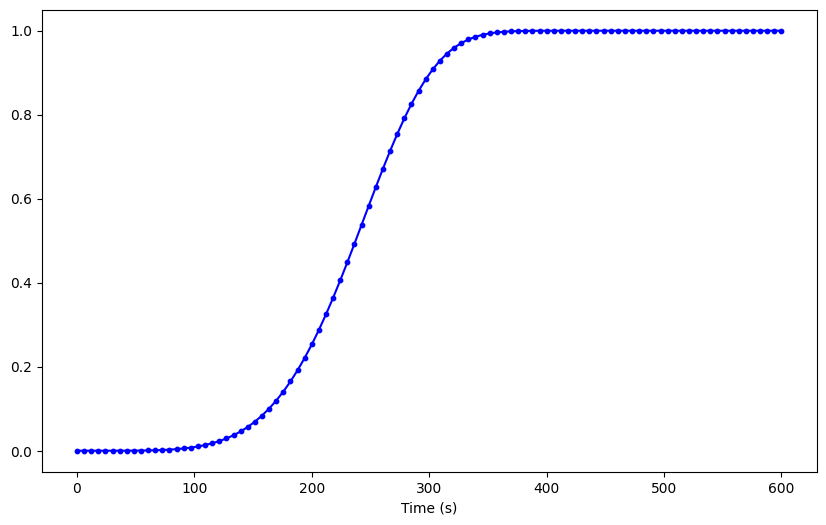

In [13]:
import numpy as np
import functools
import matplotlib.pyplot as plt

# def avrami_law(t,Ea,R,T,A,n,r_max):
#     K = A * np.exp(-Ea / (R * T))
#     d = r_max * (1 - np.exp(-K * t**n))

#     return d

def avrami_law(t,Ea,R,T,A,n):
    K = A * np.exp(-Ea / (R * T))
    d = 1 - np.exp(-K * t**n)

    return d

np.random.seed(10)
guessed_A = 1.752e-6              # Increased to speed up transformation
guessed_Ea = 55690            # Lowered to increase reaction rate
T = 453               # Higher temp for faster growth
r_max = 1 #          # Max radius 
guessed_n = 5.06
R = 8.314

TIME_MAX = 600  # seconds

# Time array
times = np.linspace(0, TIME_MAX, 100)
eq = functools.partial(avrami_law, Ea=guessed_Ea, A=guessed_A, T=T, n=guessed_n, R=R)
values = eq(times)

plt.figure(figsize=(10, 6))
plt.plot(times, values, label='Avrami Law', color='blue')
plt.scatter(times, values, color='blue', s=10)
plt.xlabel('Time (s)')

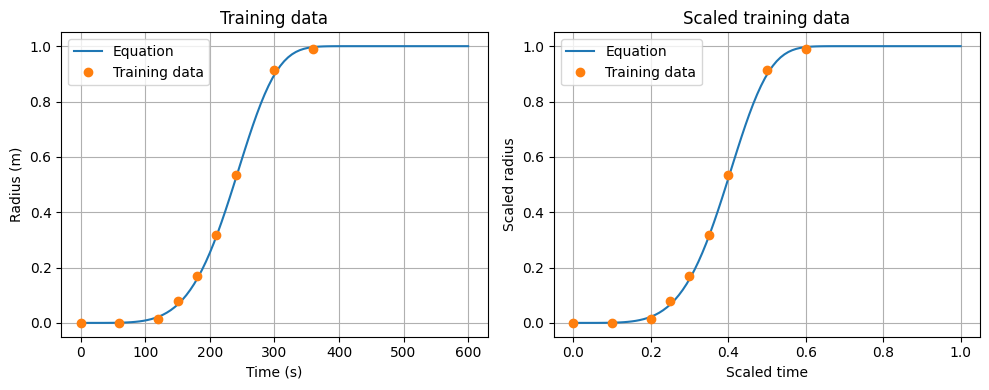

In [14]:

# Time array
gt_times_X = np.linspace(0, TIME_MAX, 100)
eq = functools.partial(avrami_law, Ea=guessed_Ea, A=guessed_A, T=T, n=guessed_n, R=R)
gt_d_Y = eq(gt_times_X) # * 1e9


## Data from concentration paper
data = [[0,0],[60,0],[120,0.0156],[150,0.078],[180,0.17],[210,0.317],[240,0.536],[300,0.913],[360,0.989]]
data = torch.tensor(data, dtype=torch.float32)
train_times_X = data[:, 0].reshape(-1, 1) # * 60
train_d_Y = data[:, 1].reshape(-1, 1) # * 1e-9


# Scale data
scaler_X = TorchMinMaxScaler()
scaler_Y = TorchMinMaxScaler()

# Fit and transform the training data
eq_times_X_scaled = scaler_X.fit_transform(gt_times_X.reshape(-1, 1)).type(torch.float32)
eq_d_Y_scaled = scaler_Y.fit_transform(gt_d_Y.reshape(-1, 1)).type(torch.float32)

# Transform test data using the already fitted scalers
train_times_X_scaled = scaler_X.transform(train_times_X.reshape(-1, 1)).type(torch.float32)
train_d_Y_scaled = scaler_Y.transform(train_d_Y.reshape(-1, 1)).type(torch.float32)


# Plot
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(gt_times_X, gt_d_Y, label="Equation")
plt.plot(train_times_X, train_d_Y , 'o', label="Training data")
# noisy data
plt.grid()
plt.legend()
plt.title("Training data")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.subplot(1, 2, 2)
plt.plot(eq_times_X_scaled, eq_d_Y_scaled, label="Equation")
plt.plot(train_times_X_scaled.cpu().numpy(), train_d_Y_scaled.cpu().numpy() , 'o', label="Training data")
plt.grid()
plt.legend()
plt.title("Scaled training data")
plt.xlabel("Scaled time")
plt.ylabel("Scaled radius")
plt.tight_layout()
plt.show(block=False)

Optimized Ea: 53948.37 J/mol
Optimized A: 1.10e-06 m/s
Optimized n: 5.07
Standard deviation of Ea: 504.66 J/mol
Standard deviation of A: 4.81e-09 m/s
Standard deviation of n: 3.52


/tmp/ipykernel_3881766/2416868395.py:16: RuntimeWarning: overflow encountered in exp
  K = A * np.exp(-Ea / (R * T))
/tmp/ipykernel_3881766/2416868395.py:17: RuntimeWarning: invalid value encountered in multiply
  d = 1 - np.exp(-K * t**n)
/tmp/ipykernel_3881766/2416868395.py:17: RuntimeWarning: overflow encountered in exp
  d = 1 - np.exp(-K * t**n)
/tmp/ipykernel_3881766/2416868395.py:17: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = 1 - np.exp(-K * t**n)


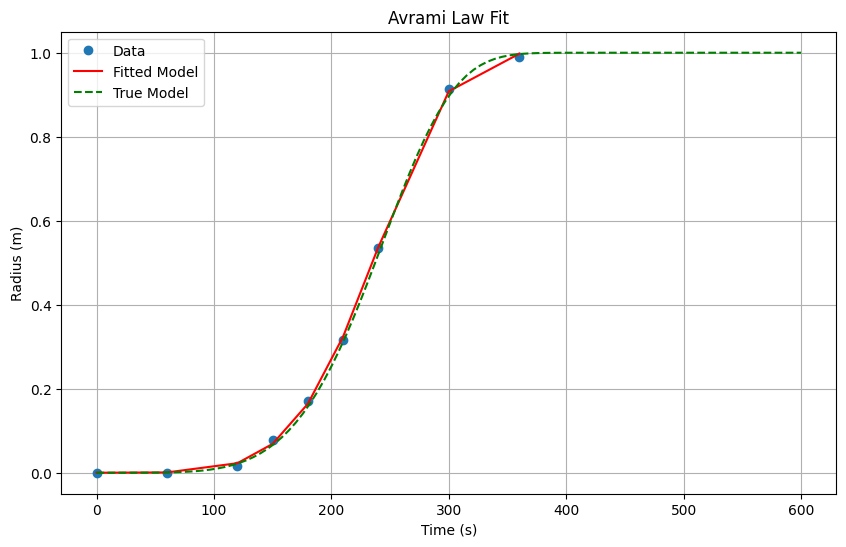

In [15]:
# Estimation parameters

import numpy as np
from scipy.optimize import least_squares

# === Data from concentration paper ===
data_np = data.cpu().numpy()
train_times_X = data[:, 0].reshape(-1, 1)
train_d_Y      = data[:, 1].reshape(-1, 1)

# Convert PyTorch tensors to NumPy arrays for SciPy
times = train_times_X.flatten().numpy()
X     = train_d_Y.flatten().numpy()

def avrami_law(t,Ea,R,T,A,n):
    K = A * np.exp(-Ea / (R * T))
    d = 1 - np.exp(-K * t**n)

    return d

# perform a least squares fit
def residuals(params, t, d):
    Ea, A, n = params
    R = 8.314
    d_model = avrami_law(t, Ea, R, T, A, n)
    return d - d_model
# Initial guess for parameters
initial_guess = [guessed_Ea, guessed_A, guessed_n]
# Perform least squares optimization
res = least_squares(residuals, initial_guess, args=(times, X), method='lm')


# Extract optimized parameters
Ea_opt, A_opt, n_opt = res.x

J = res.jac
cov = np.linalg.inv(J.T.dot(J))
var = np.sqrt(np.diagonal(cov))
std = var ** 0.5

print(f"Optimized Ea: {Ea_opt:.2f} J/mol")
print(f"Optimized A: {A_opt:.2e} m/s")
print(f"Optimized n: {n_opt:.2f}")
print(f"Standard deviation of Ea: {std[0]:.2f} J/mol")
print(f"Standard deviation of A: {std[1]:.2e} m/s")
print(f"Standard deviation of n: {std[2]:.2f}")

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(train_times_X, X, 'o', label='Data')
plt.plot(train_times_X, avrami_law(train_times_X, Ea_opt, R, T, A_opt, n_opt), label='Fitted Model', color='red')
plt.plot(gt_times_X, gt_d_Y, label='True Model', color='green', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Radius (m)')
plt.title('Avrami Law Fit')
plt.legend()
plt.grid()
plt.show(block=False)


In [16]:
import os


vannilla_pretrained = "vanilla_pretrained_concentration.pth"
vanilla = DiscoveryNet(1, 3, loss2=None, loss2_weight=1, epochs=30000, lr=1e-4).to(DEVICE)
retrain = True
if os.path.exists(vannilla_pretrained):
    try:
        vanilla.load_state_dict(torch.load(vannilla_pretrained))
        print("Loaded pretrained model")
        retrain = False
    except Exception as e:
        print("Error loading pretrained model, retraining" , e)    

if retrain:
    losses = vanilla.fit(train_times_X_scaled.to(DEVICE), train_d_Y_scaled.to(DEVICE), scaler_Y)
    plt.plot(losses)
    plt.yscale('log')
    torch.save(vanilla.state_dict(), vannilla_pretrained)


Loaded pretrained model


Epoch 0/100000, loss: 0.168757 - data_loss: 0.167613 - physic_loss: 0.001145 - Ea=30002.99, A=1.00e-04, n=1.50, r_max=8.00e-09
Epoch 10000/100000, loss: 0.006215 - data_loss: 0.003001 - physic_loss: 0.003214 - Ea=26852.92, A=1.16e-04, n=2.93, r_max=8.00e-09
Epoch 20000/100000, loss: 0.004466 - data_loss: 0.001545 - physic_loss: 0.002922 - Ea=57852.58, A=5.69e-05, n=4.55, r_max=8.00e-09
Epoch 30000/100000, loss: 0.003706 - data_loss: 0.001055 - physic_loss: 0.002651 - Ea=69768.90, A=4.74e-05, n=5.16, r_max=8.00e-09
Epoch 40000/100000, loss: 0.003255 - data_loss: 0.000800 - physic_loss: 0.002455 - Ea=70125.31, A=4.72e-05, n=5.17, r_max=8.00e-09
Epoch 50000/100000, loss: 0.002985 - data_loss: 0.000647 - physic_loss: 0.002338 - Ea=70215.52, A=4.71e-05, n=5.18, r_max=8.00e-09
Epoch 60000/100000, loss: 0.002801 - data_loss: 0.000546 - physic_loss: 0.002255 - Ea=69088.64, A=4.79e-05, n=5.11, r_max=8.00e-09
Epoch 70000/100000, loss: 0.002669 - data_loss: 0.000473 - physic_loss: 0.002196 - Ea=6

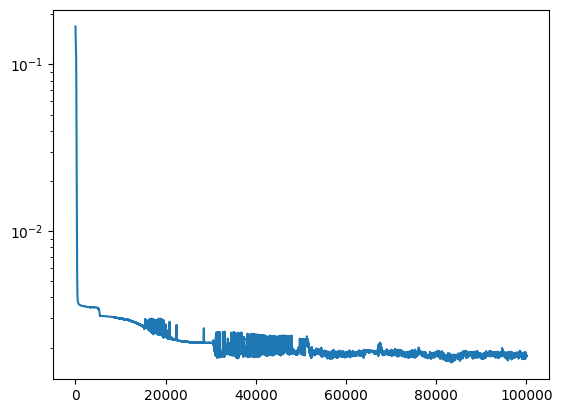

In [17]:
import torch.nn.functional as F


def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def positive_activation(x, offset=1e-6):
    # First apply softplus, then a bias offset, then optionally exponentiate for sharper contrast
    return torch.exp(F.softplus(x)) + offset

def physics_loss(model: torch.nn.Module):
    global PHYSICAL_LOSS_SCALING_FACTOR

    # Create time input for PINN
    ts = torch.linspace(0, TIME_MAX, steps=100, dtype=torch.float32).view(-1, 1).to(DEVICE).requires_grad_(True)
    ts_scaled = scaler_X.transform(ts)

    # Predict radius
    out = model(ts_scaled)
    # d, Ea_net, A_net, n_net = out[:, 0], out[:, 1], out[:, 2], out[:, 3]  # [-1, 1] [0, 1]
    d = out
    d = scaler_Y.inverse_transform(d)
    
    #Ea = torch.nn.functional.softplus(Ea_net) * 1e5
    #A = torch.nn.functional.softplus(A_net) * 1e-3
    # Ea = Ea_net * 1e5 
    # A = A_net * 1e-3

    Ea = model.Ea
    A =  model.A
    n =  model.n
    r_max = model.r_max

    # Compute model's derivative wrt time
    dd = torch.autograd.grad(
        d, ts, 
        grad_outputs=torch.ones_like(d), 
        create_graph=True
    )[0]

    # Compute K
    K = A * torch.exp(-Ea / (R * T))
    # Theoretical Avrami derivative
    derived_eq = K * n * ts.pow(n - 1) * torch.exp(-K * ts.pow(n))

    pde_residual = dd - derived_eq
    # pde_residual = pde_residual * 1e12

    physical_loss = torch.mean(pde_residual**2)

    if PHYSICAL_LOSS_SCALING_FACTOR is None:
        # Get the maximum residual value as a float
        val = torch.max(physical_loss).item()
        # Compute the order-of-magnitude exponent. For a value like 5.23e-6,
        # math.log10(val) ≈ -5.28, and floor(-5.28) gives -6.
        exponent = -math.floor(math.log10(val))
        # Set the scaling factor as 10 raised to the computed exponent.
        # PHYSICAL_LOSS_SCALING_FACTOR = 10 ** exponent
        PHYSICAL_LOSS_SCALING_FACTOR = 1/abs(exponent)
        # PHYSICAL_LOSS_SCALING_FACTOR = 1e10

        # PROBLEM: when 1/exponent is too small, loss is too "flat" and less sensitive to gradient descent
        # alpha = 1/abs(exponent)  # computed as before
        # delta = 0.1  # adjust this value as needed
        # alpha_eff = min(alpha + delta, 1.0)
        # # regularized_loss = scaled_loss ** alpha_eff
        # PHYSICAL_LOSS_SCALING_FACTOR = alpha_eff
    
    physical_loss = torch.pow(physical_loss, PHYSICAL_LOSS_SCALING_FACTOR)
    # physical_loss = torch.nn.functional.softplus(physical_loss)

    return physical_loss

# PHYSICAL_LOSS_SCALING_FACTOR = 1e-12
PHYSICAL_LOSS_SCALING_FACTOR = None

set_seed(0)
scaler_X = scaler_X.to(DEVICE)
scaler_Y = scaler_Y.to(DEVICE)
curr_train_times_X = train_times_X_scaled.to(DEVICE)
curr_train_d_Y = train_d_Y_scaled.to(DEVICE)


# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=150000, lr=1e-4).to(DEVICE)
# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=10000, lr=1e-4).to(DEVICE)
# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=100000, lr=1e-4).to(DEVICE)
net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=0.01, epochs=100000, lr=1e-4).to(DEVICE)
# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=2, epochs=500000, lr=1e-5).to(DEVICE)

# net.A = A_opt + (A_opt * 0.2)
# net.Ea = Ea_opt + (Ea_opt * 0.2)
# net.n = n_opt + (n_opt * 0.2)

losses = net.fit(curr_train_times_X, curr_train_d_Y, scaler_Y)

plt.plot(losses)
plt.yscale('log')

In [18]:
print(net.Ea.item(), net.A.item(), net.n.item(), net.r_max.item())

# print(positive_activation(net.Ea).item(), positive_activation(net.A).item(), positive_activation(net.n).item())

67488.140625 4.902638465864584e-05 5.031580448150635 8.000005102815066e-09


Predicted A: 4.9026e-05, Guess A: 1.1039e-06  -  difference: 4.7923e-05
Predicted Ea: 67488.14, Guess Ea: 53948.37  -  difference: 13539.77
Predicted n: 5.0316, Guess n: 5.0688  -  difference: -0.04


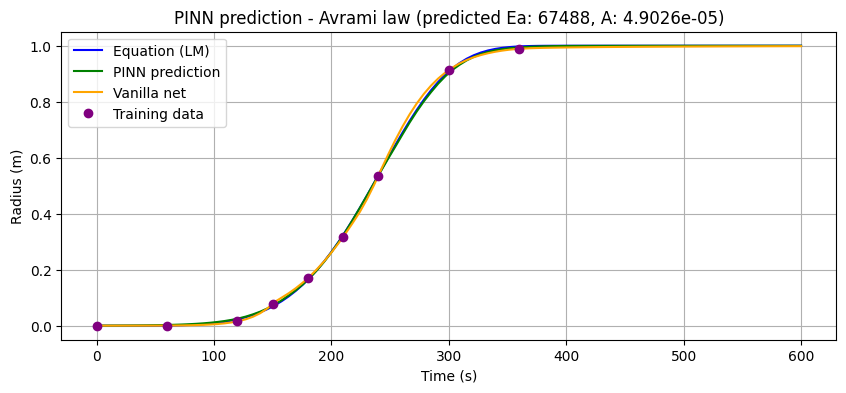

/tmp/ipykernel_3881766/2416868395.py:17: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = 1 - np.exp(-K * t**n)


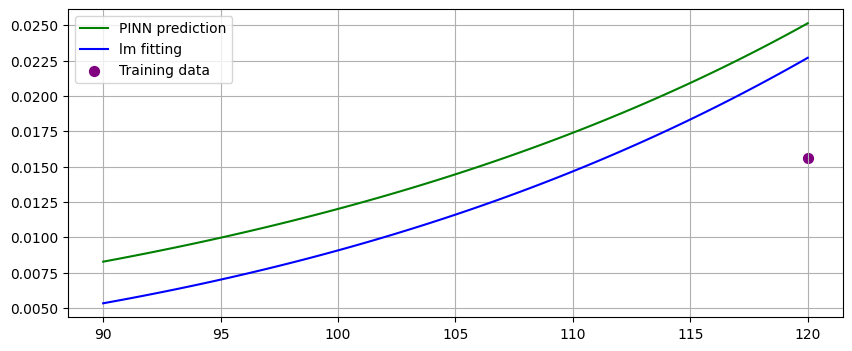

In [36]:
# plot the prediction on gt data

d = net.predict(eq_times_X_scaled)
d = torch.tensor(d, dtype=torch.float32, device=DEVICE)
d = scaler_Y.inverse_transform(d)
d = d.cpu().numpy()
Ea_net = net.Ea.item()
A_net = net.A.item()
n_net = net.n.item()
r_max_net = net.r_max.item()

# expected:
Ea = Ea_net
A = A_net
n = n_net
r_max = r_max_net

# Ea_opt, A_opt, n_opt
A_expected = A_opt
Ea_expected = Ea_opt
n_expected = n_opt
# r_max_expected = r_max_opt = r_max

print(f"Predicted A: {A:.4e}, Guess A: {A_expected:.4e}  -  difference: {(A - A_expected):.4e}")
print(f"Predicted Ea: {Ea:.2f}, Guess Ea: {Ea_expected:.2f}  -  difference: {(Ea - Ea_expected):.2f}")
print(f"Predicted n: {n_net:.4f}, Guess n: {n_expected:.4f}  -  difference: {(n - n_expected):.2f}")
# print(f"Predicted r_max: {r_max:.2e}, Guess r_max: {r_max_expected:.2e}  -  abs difference: {abs(r_max - r_max_expected):.2e}")

vanilla_pred = vanilla.predict(eq_times_X_scaled)
vanilla_pred = torch.tensor(vanilla_pred, dtype=torch.float32, device=DEVICE)
vanilla_d = vanilla_pred[:, 0]
vanilla_d = scaler_Y.inverse_transform(vanilla_d)
vanilla_d = vanilla_d.cpu().numpy()
plt.figure(figsize=(10, 4))
# plt.subplot(1, 2, 1)
eq_fitting = functools.partial(avrami_law, A=A_opt, Ea=Ea_opt, T=T, n=n_opt, R=R)

plt.plot(gt_times_X, eq_fitting(gt_times_X), label="Equation (LM)", color='blue')
plt.plot(gt_times_X, d, label="PINN prediction", color="green")
plt.plot(gt_times_X, vanilla_d, label="Vanilla net", color="orange")
# plot train data
plt.plot(train_times_X, train_d_Y , 'o', label="Training data", color="purple")
plt.title(f"PINN prediction - Avrami law (predicted Ea: {Ea:.0f}, A: {A:.4e})")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.grid()
plt.legend()
plt.show()


# # plot all Ea and A values
# plt.figure(figsize=(10, 4))
# plt.subplot(1, 3, 1)
# plt.plot(gt_times_X, Ea, label="Ea")
# plt.legend()
# plt.grid()
# plt.subplot(1, 3, 2)
# plt.plot(gt_times_X, A, label="A")
# plt.legend()
# plt.grid()
# plt.subplot(1, 3, 3)
# plt.plot(gt_times_X, n, label="n")
# plt.legend()
# plt.grid()
# plt.show()


plt.figure(figsize=(10, 4))
# plot avrami eq using predicted A and Ea
times = torch.linspace(90, 120, 100)
# times = torch.linspace(350, 400, 100)
# times = torch.linspace(0, TIME_MAX, 100)

times_s = scaler_X.transform(times.reshape(-1, 1)).type(torch.float32).to(DEVICE)
times_s = times_s.reshape(-1, 1)
d = net.predict(times_s)
d = torch.tensor(d, dtype=torch.float32, device=DEVICE)
d = scaler_Y.inverse_transform(d)
d = d.cpu().numpy()
plt.plot(times.cpu().numpy(), d, label="PINN prediction", color="green")

plt.plot(times, eq_fitting(times), label=f"lm fitting", color='blue')
plt.scatter(train_times_X[2], train_d_Y[2], color="purple", s=50, label="Training data")
# plt.scatter(times.cpu().numpy(), eq_d_Y, color='red', s=10)
plt.legend()
plt.grid()
plt.show()

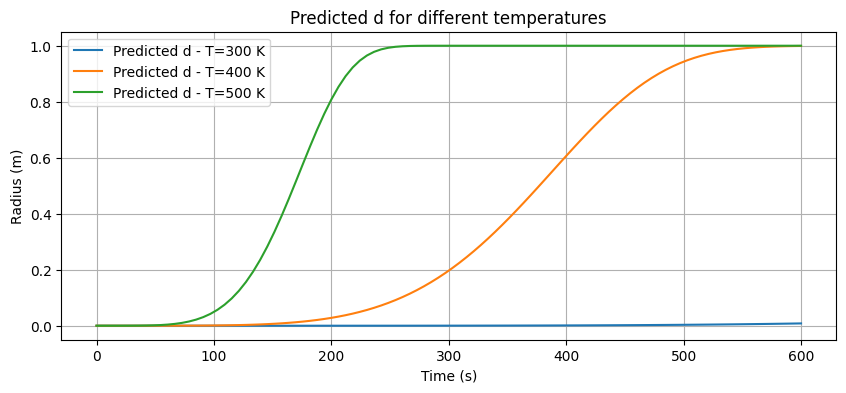

In [20]:

eq_temp = functools.partial(avrami_law, A=A, Ea=Ea, n=n, R=R)

times = np.linspace(0, TIME_MAX, 100)

plt.figure(figsize=(10, 4))
for temp in [300, 400, 500]:
    expeced_d = eq_temp(times, T=temp)
    plt.plot(times, expeced_d, label=f"Predicted d - T={temp} K")

plt.title("Predicted d for different temperatures")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.legend()
plt.grid()
plt.show()

## ONE WAY
t = [0, 1, 2, ...] # seconds for a total of N steps
d, Ea, A = nn(t)

at the end you have
- d -> [N]
- Ea -> [N] mean() std()
- A -> [N] mean() std()
- Ea and A uncertainty (std) -> DEPENDENT ON THE TIME

## SECOND WAY
t = [0, 1, 2, ...] # seconds for a total of N steps
d = nn(t)
Ea = nn.Ea # learned 
A = nn.A # learned 

- d -> [N]
- NO UNCERTAINTY IN Ea
- INDEPENDENT FROM THE TIME

/tmp/ipykernel_3881766/2416868395.py:17: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  d = 1 - np.exp(-K * t**n)


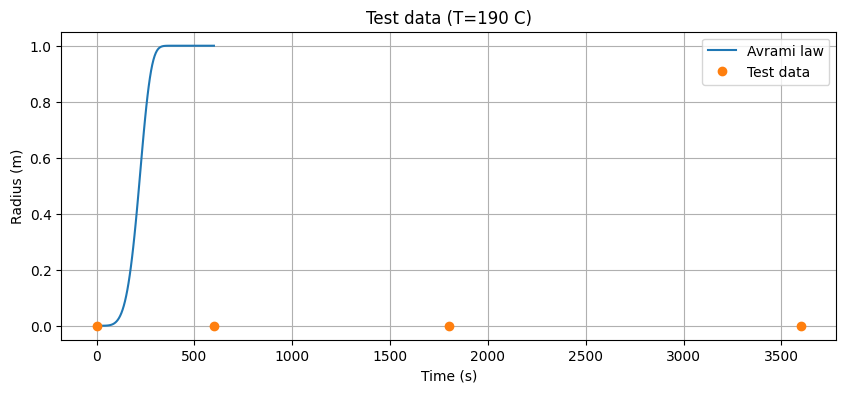

In [21]:
test_T = 190 + 273.15
test_data = [
    [0,0],
    [10*60,10.5],
    [30*60,12.9],
    [60*60,13.9]
]
test_times = torch.linspace(0, TIME_MAX, 100)
test_data = torch.tensor(test_data, dtype=torch.float32)
# test_r_max = 14e-9

predicted_Ea = Ea
predicted_A = A
predicted_n = n
predicted_r_max = 1.4e-8

plt.figure(figsize=(10, 4))
eq_test = functools.partial(avrami_law, A=predicted_A, Ea=predicted_Ea, n=predicted_n, R=R)
law = eq_test(test_times, T=test_T)
plt.plot(test_times, law, label="Avrami law")
plt.plot(test_data[:, 0], test_data[:, 1] * 1e-9, 'o', label="Test data")
plt.title("Test data (T=190 C)")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.legend()
plt.grid()
plt.show()

